In [12]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
import random

In [13]:
class state(TypedDict):
    marks:int
    result:str

In [14]:
def check_score(state:TypedDict)->dict:
    marks=random.randint(1,100)
    return {
        "marks":marks
    }
def declare_fail(state:TypedDict)->dict:
    result="fail"
    return {"result":result}
    

def declare_average(state:TypedDict)->dict:
    result="average"
    return {"result":result}

def declare_good(state:TypedDict)->dict:
    result="good"
    return {"result":result}

def conditionaEdge(state:TypedDict)->str:
    marks=state["marks"]
    if(marks<35):
        return "declare_fail"
    elif marks>=35 and marks <=75:
        return "declare_average"
    else:
        return "declare_good"


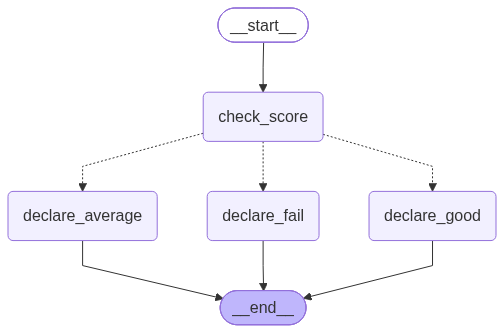

In [15]:
graph=StateGraph(state)
graph.add_node("check_score",check_score)
graph.add_node("declare_fail",declare_fail)
graph.add_node("declare_average",declare_average)
graph.add_node("declare_good",declare_good)
graph.add_edge(START,"check_score")
graph.add_conditional_edges("check_score",conditionaEdge,{
        "declare_fail": "declare_fail",
        "declare_average": "declare_average",
        "declare_good": "declare_good"
    })
graph.add_edge("declare_fail",END)
graph.add_edge("declare_good",END)
graph.add_edge("declare_average",END)
workflow=graph.compile()
workflow

In [20]:
initial_state={"marks":0,"result":""}
final_state=workflow.invoke(initial_state)
print(final_state)

{'marks': 89, 'result': 'good'}
